# Paysages de perte et descente de gradient

Un complément à la présentation 14

Marcel Turcotte  
2026-10-31

La rétropropagation calcule un gradient. L’utilité de la mise à jour
obtenue dépend aussi de la forme de la fonction objectif, des paramètres
initiaux et du taux d’apprentissage. Ce carnet complète la présentation
14 avec des **paysages de perte** (*loss landscapes*) unidimensionnels
que nous pouvons examiner entièrement.

La discussion s’inspire de <a
href="https://www.youtube.com/playlist?list=PLUl4u3cNGP63URZnh5iqBzDTDYPUTQT-8"
class="external" data-icon="true">MIT 6.S191: Introduction to Deep
Learning</a>; les fonctions et les expériences ci-dessous servent
d’illustrations pédagogiques. Un réseau de neurones possède généralement
de nombreux paramètres : ces graphiques représentent des situations
simplifiées plutôt que des surfaces complètes de perte de réseaux.

## Suivre un gradient

La mise à jour est $\theta_{t+1}=\theta_t-\alpha J'(\theta_t)$. La
fonction auxiliaire consigne les valeurs du paramètre sans écrêtage,
sauf si un seuil est fourni explicitement. Si une fonction objectif
délibérément non lisse n’a pas de dérivée finie à une itération, la
trajectoire s’y arrête.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_1d(gradient, start, learning_rate, steps, clip_value=None):
    trajectory = [float(start)]
    for _ in range(steps):
        g = float(gradient(trajectory[-1]))
        if not np.isfinite(g):
            break  # La fonction simplifiée n'a pas de dérivée finie ici.
        if clip_value is not None:
            g = np.clip(g, -clip_value, clip_value)
        trajectory.append(trajectory[-1] - learning_rate * g)
    return np.asarray(trajectory)

def plot_landscape(objective, trajectory, ax, title):
    left = min(-1.2, trajectory.min())
    right = max(1.2, trajectory.max())
    padding = 0.05 * (right - left)
    theta = np.linspace(left - padding, right + padding, 800)
    ax.plot(theta, objective(theta), color='black', linewidth=1.5)
    ax.plot(trajectory, objective(trajectory), 'o-', color='#377eb8',
            markersize=3, linewidth=0.8, alpha=0.65)
    ax.scatter(trajectory[0], objective(trajectory[0]), color='#4daf4a',
               s=45, zorder=4, label='Départ')
    ax.scatter(trajectory[-1], objective(trajectory[-1]), color='#d95f02',
               s=45, zorder=5, label='Fin')
    ax.set(title=title, xlabel=r'$\theta$', ylabel=r'$J(\theta)$')
    ax.grid(alpha=0.25)
    return theta

## Trois cas contrastés

L’exemple à région plate est
$J(\theta)=(\operatorname{ReLU}(\theta)-1)^2$. Tout $\theta$ négatif
donne une perte de 1 et une dérivée nulle, mais $\theta=1$ donne une
perte nulle. C’est une région plate sous-optimale, et non une fonction
objectif constante partout. À zéro, la dérivée ordinaire n’est pas
définie; cet exemple utilise la convention habituelle du gradient nul à
travers ReLU.

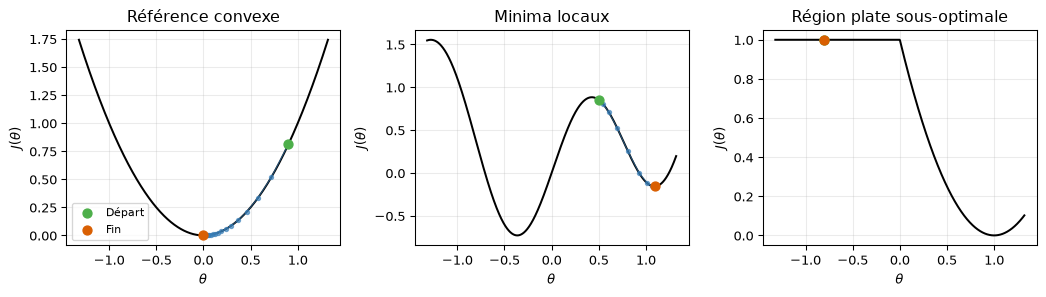

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
overview = [
    ('Référence convexe', lambda t: t**2, lambda t: 2*t, 0.9, 0.1),
    ('Minima locaux', lambda t: 0.8*np.sin(4*t)+0.5*t**2,
     lambda t: 3.2*np.cos(4*t)+t, 0.5, 0.05),
    ('Région plate sous-optimale', lambda t: (np.maximum(0, t)-1)**2,
     lambda t: 2*(t-1) if t > 0 else 0.0, -0.8, 0.1)
]
for ax, (title, objective, gradient, start, rate) in zip(axes, overview):
    trajectory = gradient_descent_1d(gradient, start, rate, steps=60)
    plot_landscape(objective, trajectory, ax, title)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

L’exemple convexe approche son minimum. L’exemple non convexe atteint un
minimum local déterminé par le point initial. La valeur initiale
négative de l’exemple ReLU ne reçoit aucun signal de gradient pour
quitter sa région plate. Un gradient nul ne garantit pas à lui seul une
règle de prédiction globalement optimale.

En dimension supérieure, un point stationnaire peut aussi être un point
de selle : la fonction objectif augmente dans certaines directions et
diminue dans d’autres. Les illustrations unidimensionnelles ne peuvent
montrer toute cette géométrie.

## Un atlas de fonctions objectif simplifiées

Les autres exemples comprennent une pointe, une marche et des sauts pour
illustrer les cas où la différentiabilité ordinaire fait défaut. Les
réseaux composés de transformations affines et d’activations continues
comme ReLU produisent des prédictions continues; les exemples
discontinus ci-dessous sont délibérément plus pathologiques.

In [4]:
def cusp_gradient(theta):
    if theta == 0:
        return np.nan
    return 1.1 * np.sign(theta) / np.sqrt(abs(theta))

scenarios = [
    dict(title='Référence convexe', objective=lambda t: t**2,
         gradient=lambda t: 2*t, start=0.9, learning_rate=0.1),
    dict(title='Minima locaux', objective=lambda t: 0.8*np.sin(4*t) + 0.5*t**2,
         gradient=lambda t: 3.2*np.cos(4*t) + t, start=0.5, learning_rate=0.05),
    dict(title='Région plate sous-optimale', objective=lambda t: (np.maximum(0, t)-1)**2,
         gradient=lambda t: 2*(t-1) if t > 0 else 0.0, start=-0.8, learning_rate=0.1),
    dict(title='Dérivée singulière à une pointe', objective=lambda t: 2.2*np.sqrt(np.abs(t))-1.2,
         gradient=cusp_gradient, start=0.75, learning_rate=0.05),
    dict(title='Saut discontinu', objective=lambda t: np.where(t < 0, 0.5*t-0.2, 0.5*t+0.6),
         gradient=lambda t: 0.5 if t != 0 else np.nan, start=0.8, learning_rate=0.1),
    dict(title='Plusieurs minima locaux', objective=lambda t: 0.5*np.cos(2*np.pi*t) + 0.25*t**2,
         gradient=lambda t: -np.pi*np.sin(2*np.pi*t) + 0.5*t, start=0.6, learning_rate=0.01),
    dict(title='Fonction en marche', objective=lambda t: np.where(t >= 0, 0.5, -0.5),
         gradient=lambda t: 0.0 if t != 0 else np.nan, start=0.7, learning_rate=0.1),
    dict(title='Pentes opposées avec saut', objective=lambda t: np.where(t < 0, -t-0.2, t+0.4),
         gradient=lambda t: -1.0 if t < 0 else (1.0 if t > 0 else np.nan),
         start=0.8, learning_rate=0.15)
]

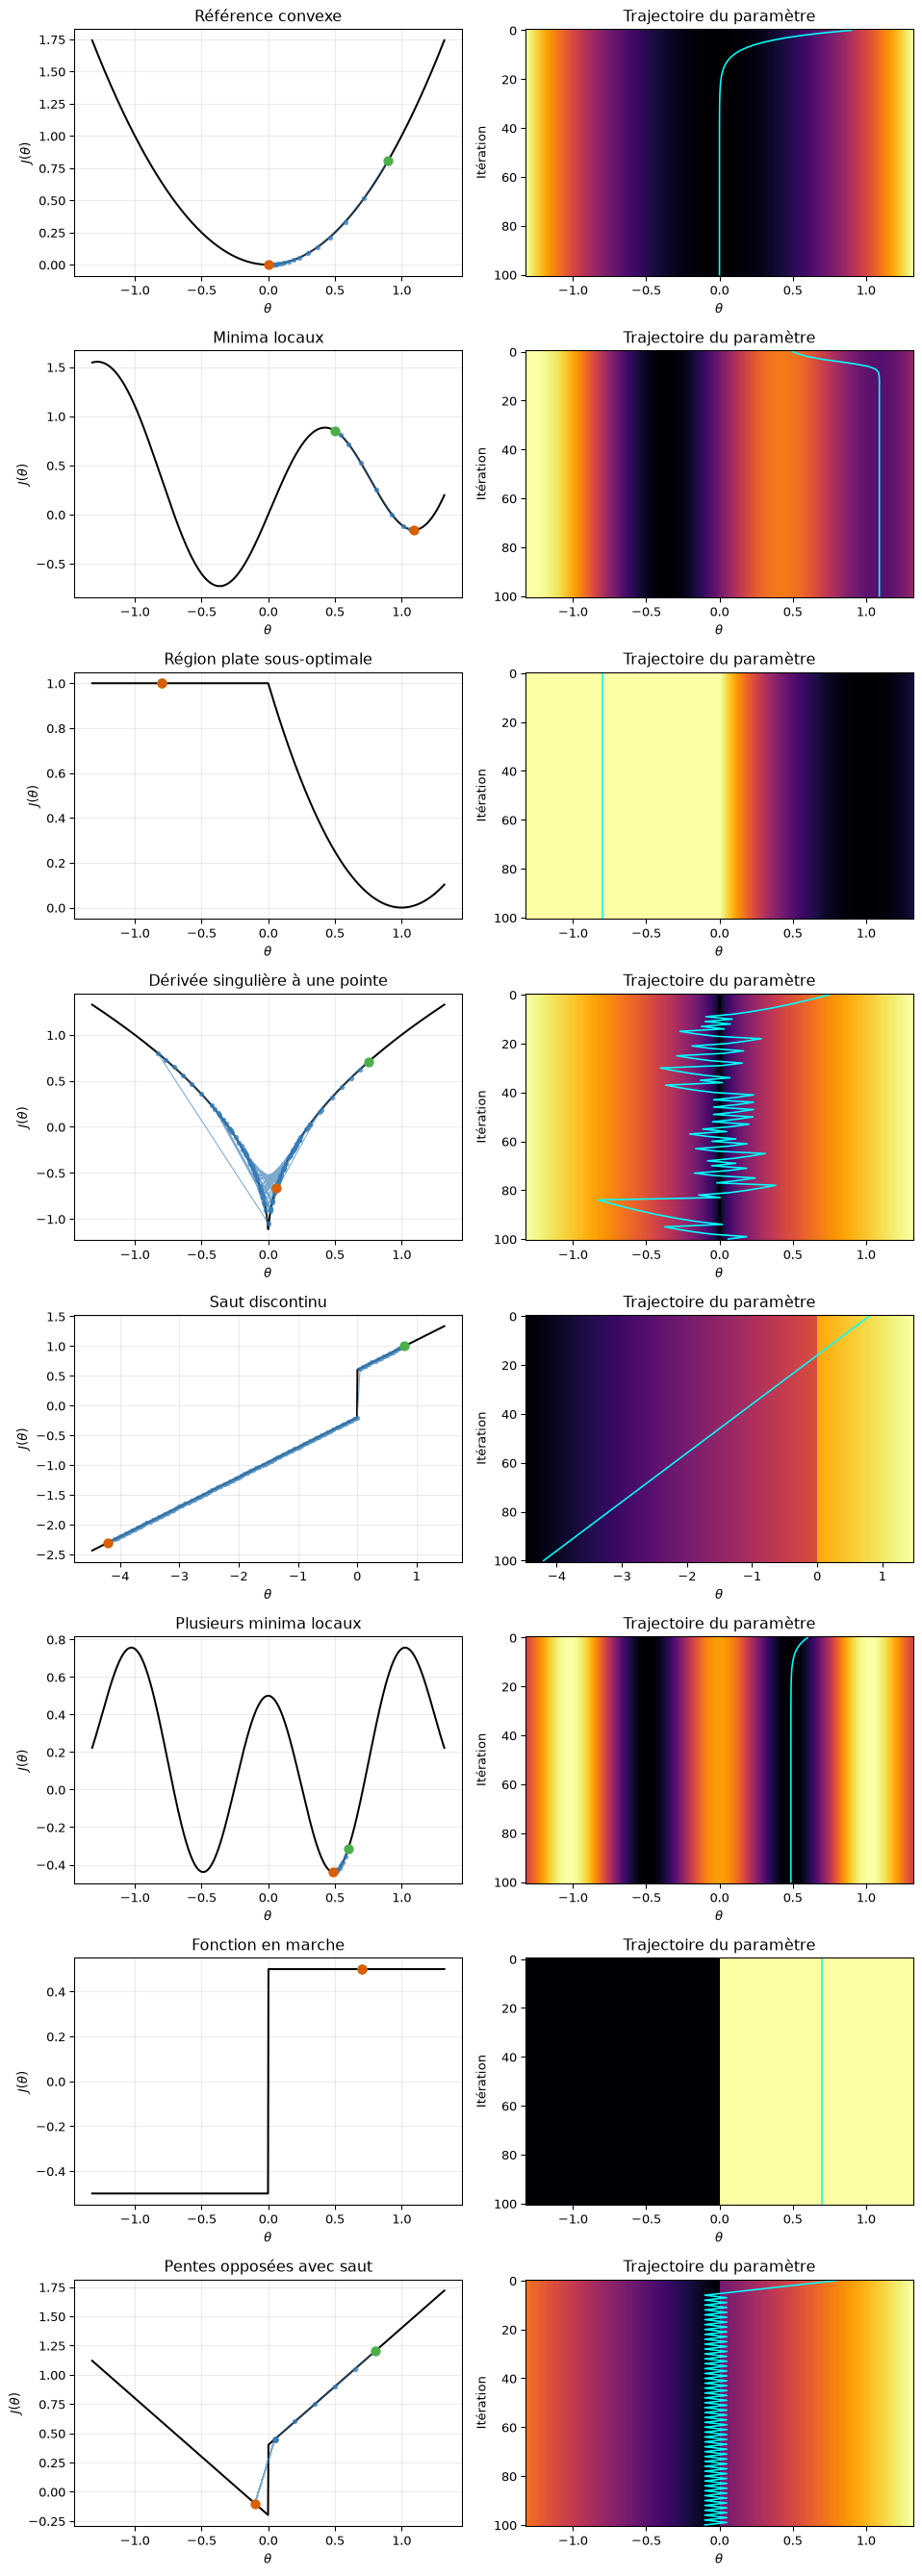

In [5]:
fig, axes = plt.subplots(len(scenarios), 2, figsize=(10, 3.5*len(scenarios)))
for index, scenario in enumerate(scenarios):
    row, column = index, 0
    trajectory = gradient_descent_1d(scenario['gradient'], scenario['start'],
                                     scenario['learning_rate'], steps=100)
    theta = plot_landscape(scenario['objective'], trajectory, axes[row, column],
                           scenario['title'])
    iterations = np.arange(len(trajectory))
    values = np.broadcast_to(scenario['objective'](theta), (len(iterations), len(theta)))
    axes[row, column+1].pcolormesh(theta, iterations, values,
                                   cmap='inferno', shading='auto')
    axes[row, column+1].plot(trajectory, iterations, color='cyan', linewidth=1.2)
    axes[row, column+1].invert_yaxis()
    axes[row, column+1].set(title='Trajectoire du paramètre', xlabel=r'$\theta$', ylabel='Itération')
fig.tight_layout()
plt.show()

Chaque carte thermique répète la **même fonction objectif
unidimensionnelle fixe** de haut en bas. L’axe horizontal représente le
paramètre et l’axe vertical l’itération. Il ne s’agit pas d’une surface
de perte à deux paramètres. Les limites des graphiques englobent la
trajectoire consignée, y compris les excursions hors de l’intervalle
initial.

La fonction avec saut et pente positive constante n’est pas bornée
inférieurement. L’exemple aux pentes opposées possède une valeur limite
inférieure non atteinte lorsqu’on approche zéro par la gauche. Ces
exemples illustrent des hypothèses d’optimisation non satisfaites, sans
affirmer que les pertes usuelles des réseaux possèdent toujours ces
propriétés.

La fonction à pointe possède une dérivée non bornée près de zéro, où
elle n’est pas définie. Il s’agit d’une **dérivée locale singulière**.
Dans un réseau profond, les **gradients explosifs** (*exploding
gradients*) peuvent plutôt résulter de produits de transformations
pendant la rétropropagation; aucune dérivée d’activation individuelle
n’a besoin d’être singulière.

## Écrêter le gradient d’une fonction à forte pente

Utilisons $J(\theta)=20\theta^2$, avec $J'(\theta)=40\theta$. Au taux
d’apprentissage $\alpha=0.08$, la mise à jour sans écrêtage multiplie la
valeur courante par $-2.2$; sa valeur absolue augmente donc.
L’**écrêtage du gradient** (*gradient clipping*) scalaire à $[-5,5]$
limite la taille de chaque mise à jour à $0.4$.

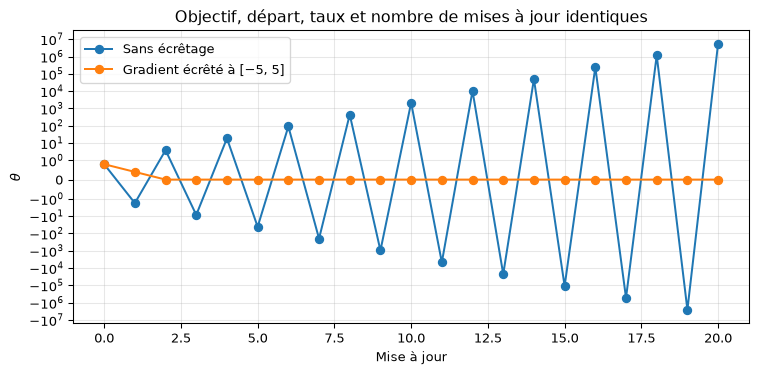

In [6]:
steep_objective = lambda t: 20*t**2
steep_gradient = lambda t: 40*t
unclipped = gradient_descent_1d(steep_gradient, 0.8, 0.08, steps=20)
clipped = gradient_descent_1d(steep_gradient, 0.8, 0.08, steps=20, clip_value=5.0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(unclipped, 'o-', label='Sans écrêtage')
ax.plot(clipped, 'o-', label='Gradient écrêté à [−5, 5]')
ax.set_yscale('symlog', linthresh=1)
ax.set(xlabel='Mise à jour', ylabel=r'$\theta$', title='Objectif, départ, taux et nombre de mises à jour identiques')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

L’axe logarithmique symétrique affiche de grandes valeurs positives et
négatives tout en conservant la région près de zéro. L’écrêtage borne le
pas; un taux d’apprentissage plus petit traiterait aussi ce cas
quadratique. Dans un réseau, l’écrêtage par norme globale redimensionne
le vecteur gradient lorsque sa norme dépasse un seuil.

## L’écrêtage ne garantit pas la convergence

La pointe de la fonction racine carrée fournit un contre-exemple :
malgré l’écrêtage, une méthode à pas constant peut continuer d’osciller
près du minimum. Comparons les deux trajectoires avec les mêmes
réglages.

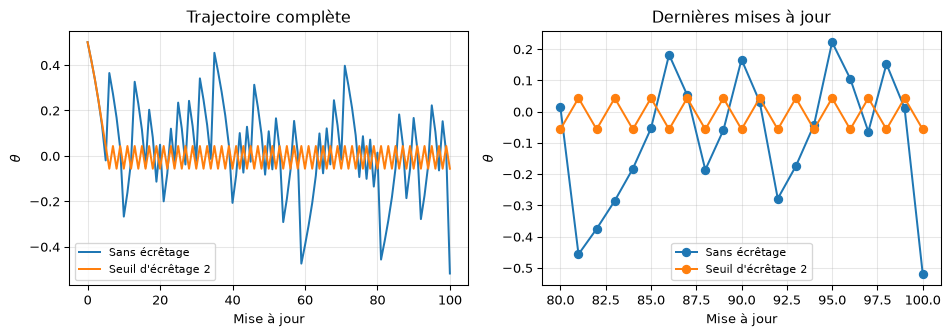

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for threshold, label in [(None, 'Sans écrêtage'), (2.0, 'Seuil d\'écrêtage 2')]:
    trajectory = gradient_descent_1d(cusp_gradient, 0.5, 0.05, steps=100,
                                     clip_value=threshold)
    axes[0].plot(trajectory, label=label)
    axes[1].plot(np.arange(80, len(trajectory)), trajectory[80:], 'o-', label=label)
axes[0].set(title='Trajectoire complète', xlabel='Mise à jour', ylabel=r'$\theta$')
axes[1].set(title='Dernières mises à jour', xlabel='Mise à jour', ylabel=r'$\theta$')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Des mises à jour bornées n’approchent pas nécessairement un minimum. Le
taux d’apprentissage et son évolution restent importants. L’écrêtage ne
restaure pas un gradient évanescent, ne supprime pas les minima locaux
et ne rend pas différentiable une fonction discontinue.

Pour réfléchir : quelles trajectoires s’arrêtent parce que leurs
gradients sont nuls, lesquelles dépendent du point initial et lesquelles
échouent parce que la mise à jour est trop grande?

[Retour à la présentation 14](index.qmd).